# Устойчивость SIFT к масштабу, ориентации и качеству

In [45]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
ROOT = Path.cwd()

## 1. Загрузка
Уменьшаем только большие снимки до 1400 px по длинной стороне. Пропорции сохраняются.
OpenCV читает цвет как BGR; для вывода через Matplotlib преобразуем его в RGB.

In [46]:
paths = sorted((ROOT / "PLANKTON").glob("*.jpg"))
images = []
for path in paths:
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Не удалось прочитать {path}")
    height, width = image.shape[:2]
    scale = min(1.0, 1400 / max(height, width))
    image = cv2.resize(image, (round(width * scale), round(height * scale)),
                       interpolation=cv2.INTER_AREA)
    images.append(image)

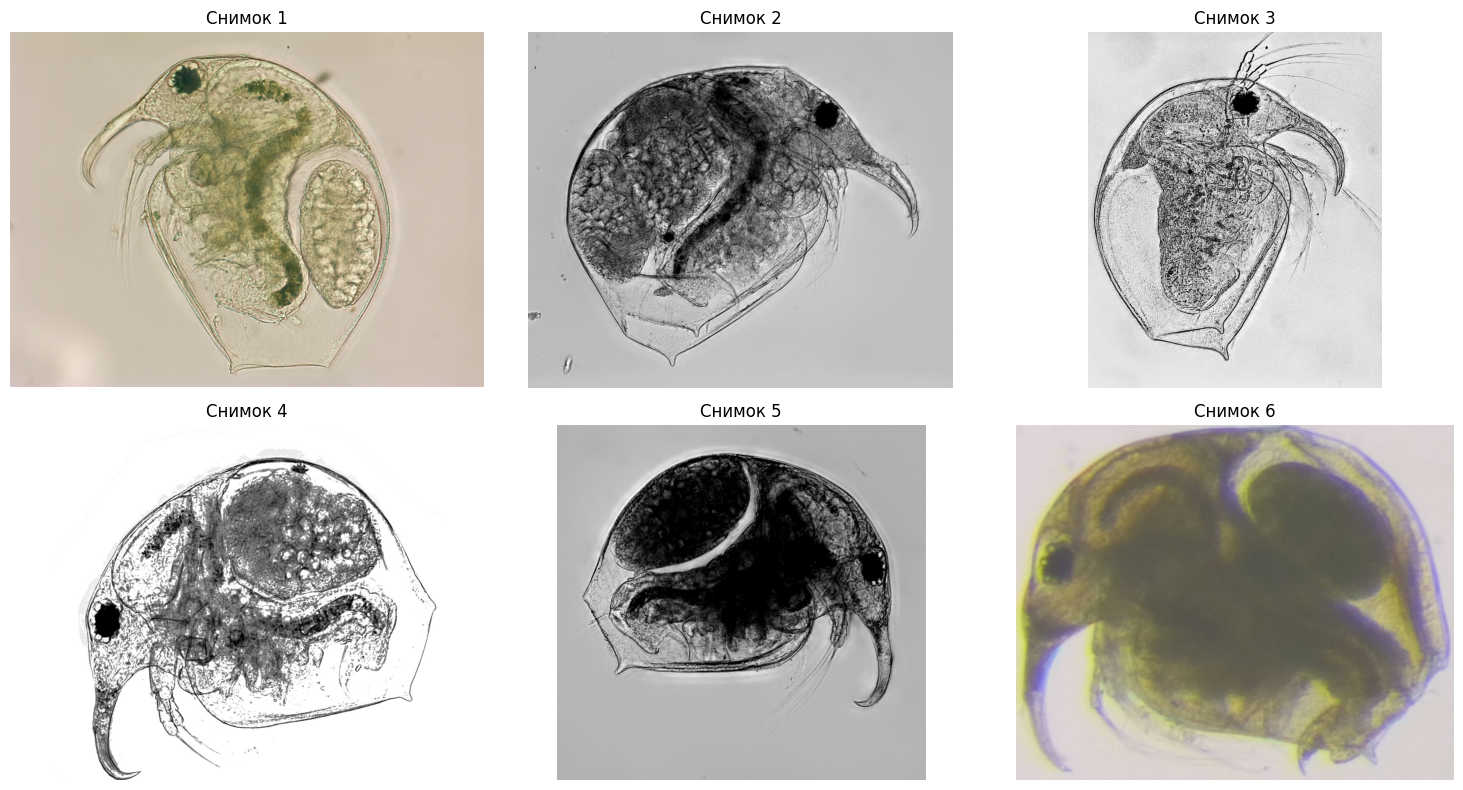

In [47]:
def show_grid(pictures, titles, columns=3):
    rows = (len(pictures) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4 * rows),
                             squeeze=False)
    for ax, picture, title in zip(axes.flat, pictures, titles):
        if picture.ndim == 2:
            ax.imshow(picture, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_grid(images, [f"Снимок {i + 1}" for i in range(len(images))])

## 2. Базовая предобработка
**Gray** оставляет яркость. **GaussianBlur 3×3** слегка подавляет мелкий шум.
**CLAHE** усиливает контраст в локальных областях; `clipLimit=2.0` ограничивает
усиление, а `tileGridSize=(8, 8)` задаёт сетку областей.
При повороте ниже применяется маска для исключения искусственных краёв холста.
Ручная разметка не используется.

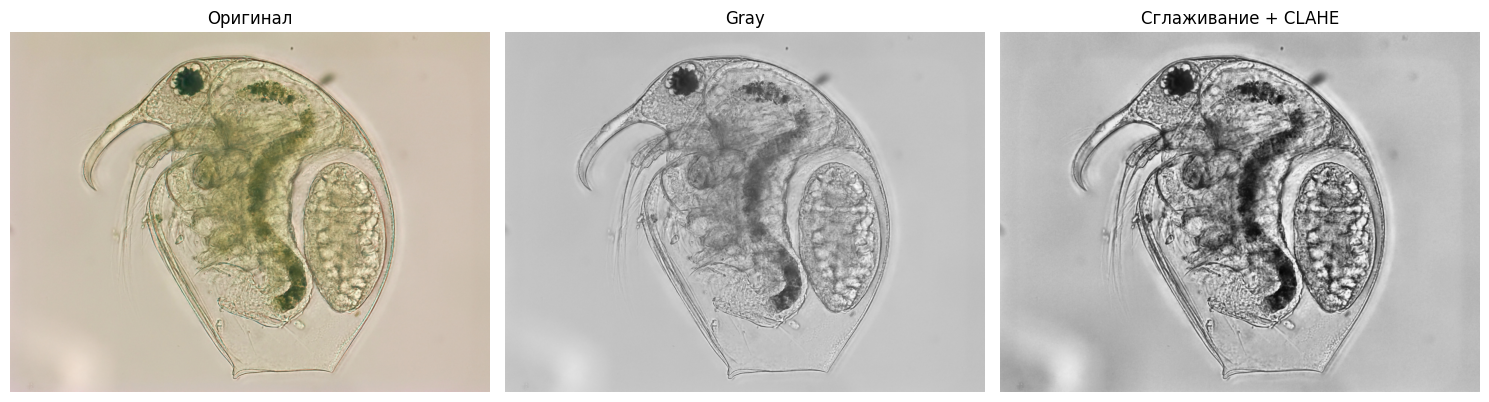

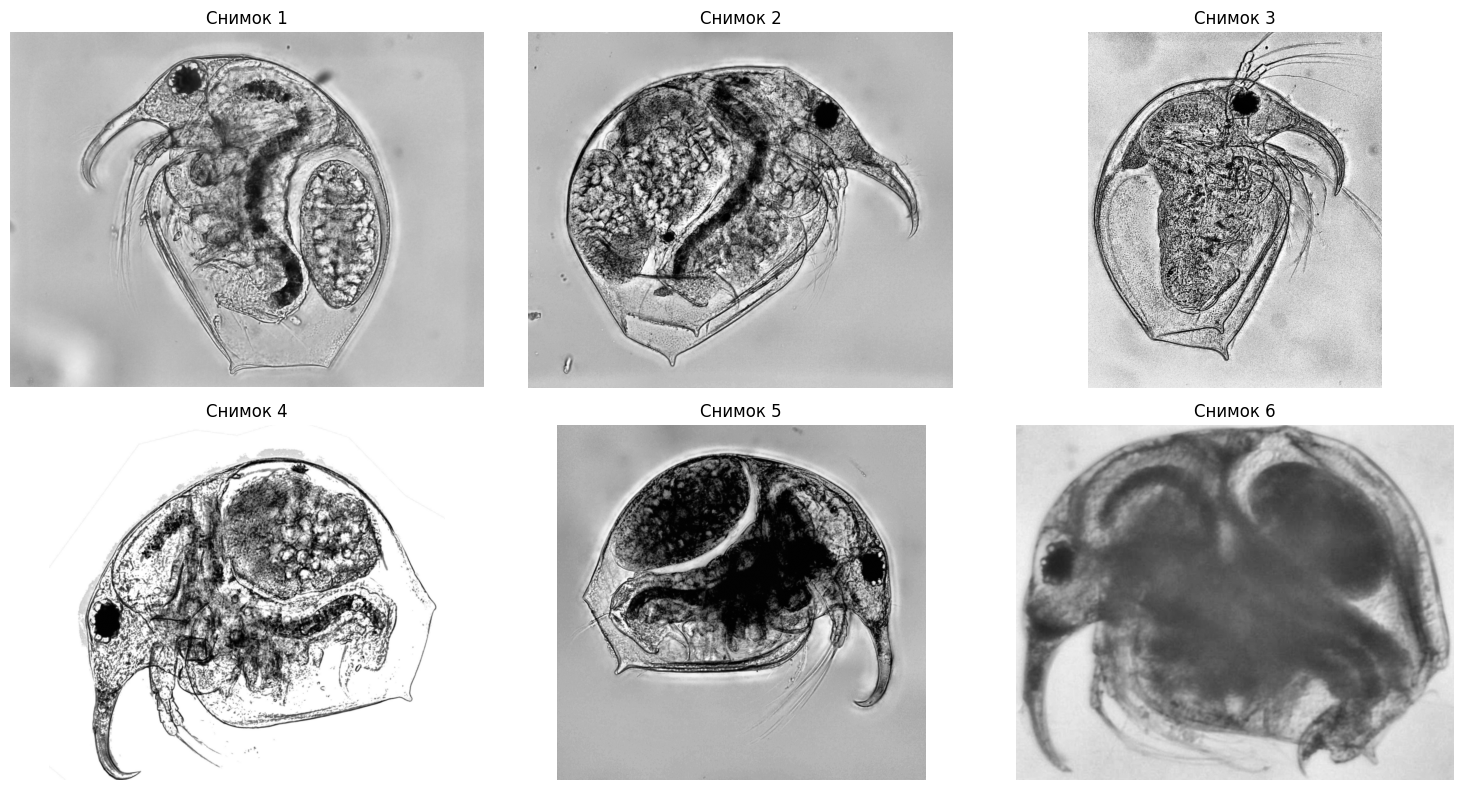

In [48]:
gray_images = []
processed = []
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

for image in images:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    normalized = clahe.apply(blurred)
    gray_images.append(gray)
    processed.append(normalized)

show_grid([images[0], gray_images[0], processed[0]],
          ["Оригинал", "Gray", "Сглаживание + CLAHE"])
show_grid(processed, [f"Снимок {i + 1}" for i in range(len(images))])

## 3. Ключевые точки и дескрипторы SIFT
- `nfeatures` - 3000 - Лимит сохраняемых сильных точек; при равных откликах возможен небольшой избыток 
- `nOctaveLayers` - 3 - Число слоёв масштаба в октаве 
- `contrastThreshold` - 0.04 - Отбор по контрасту; снижение пропускает больше слабых деталей 
- `edgeThreshold` - 10 - Отбор вытянутых деталей; увеличение ослабляет фильтрацию 
- `sigma` - 1.6 - Начальное сглаживание SIFT 

`detectAndCompute` возвращает точки и матрицу дескрипторов — по 128 чисел на точку.

In [49]:
sift = cv2.SIFT_create(nfeatures=3000, nOctaveLayers=3, contrastThreshold=0.04,
                   edgeThreshold=10, sigma=1.6)
keypoints, descriptors = [], []
for image in processed:
    points, vectors = sift.detectAndCompute(image, None)
    keypoints.append(points)
    descriptors.append(vectors)

for i, (points, vectors) in enumerate(zip(keypoints, descriptors), start=1):
    print(f"Снимок {i}: {len(points)} точек; дескрипторы: "
          f"{None if vectors is None else vectors.shape}")

Снимок 1: 3002 точек; дескрипторы: (3002, 128)
Снимок 2: 3001 точек; дескрипторы: (3001, 128)
Снимок 3: 3000 точек; дескрипторы: (3000, 128)
Снимок 4: 3001 точек; дескрипторы: (3001, 128)
Снимок 5: 3001 точек; дескрипторы: (3001, 128)
Снимок 6: 492 точек; дескрипторы: (492, 128)


In [50]:
matcher = cv2.BFMatcher(cv2.NORM_L2)

def ratio_matches(source, target):
    if source is None or target is None or len(target) < 2:
        return []
    matches = []
    for neighbors in matcher.knnMatch(source, target, k=2):
        if len(neighbors) == 2:
            best, second = neighbors
            if best.distance < 0.8 * second.distance:
                matches.append(best)
    return matches

In [51]:
pair_matches = {}

def draw_pair(i, j):
    colors = [(0, 255, 255), (255, 0, 255), (255, 255, 0),
              (0, 255, 0), (0, 140, 255), (255, 100, 100)]
    
    view = cv2.drawMatches(images[i], [], images[j], [], [], None)
    points = []
    for number, match in enumerate(pair_matches[(i, j)][:30], 1):
        x1, y1 = keypoints[i][match.queryIdx].pt
        x2, y2 = keypoints[j][match.trainIdx].pt
        a = (round(x1), round(y1))
        b = (round(x2) + images[i].shape[1], round(y2))
        color = colors[(number - 1) % len(colors)]
        cv2.line(view, a, b, (0, 0, 0), 7)
        cv2.line(view, a, b, color, 3)
        points.extend([(a, number, color), (b, number, color)])
         
    for (x, y), number, color in points:
        cv2.circle(view, (x, y), 11, (0, 0, 0), -1)
        cv2.circle(view, (x, y), 8, color, -1)
        label_x = min(x + 15, view.shape[1] - 45)
        label_y = max(y - 15, 30)
        cv2.rectangle(view, (label_x - 3, label_y - 25),
                      (label_x + 40, label_y + 6), (0, 0, 0), -1)
        cv2.putText(view, str(number), (label_x, label_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.85, color, 2)
    return view

Используем первый снимок и его искусственно изменённые копии. Это позволяет
проверить правильность совпадений по известному преобразованию. Другой экземпляр
организма или другой ракурс этим опытом не моделируются.

In [52]:
source_image = images[0]
height, width = source_image.shape[:2]
identity = np.array([[1., 0., 0.], [0., 1., 0.]])

rotation = cv2.getRotationMatrix2D((width / 2, height / 2), 45, 1.0)
new_width = int(np.ceil(abs(rotation[0, 0]) * width + abs(rotation[0, 1]) * height))
new_height = int(np.ceil(abs(rotation[0, 0]) * height + abs(rotation[0, 1]) * width))
rotation[:, 2] += [(new_width - width) / 2, (new_height - height) / 2]
rotated = cv2.warpAffine(source_image, rotation, (new_width, new_height),
                         borderValue=(255, 255, 255))
valid_rotation = cv2.warpAffine(np.full((height, width), 255, np.uint8), rotation,
                               (new_width, new_height), flags=cv2.INTER_NEAREST)
valid_rotation = cv2.erode(valid_rotation, np.ones((41, 41), np.uint8))

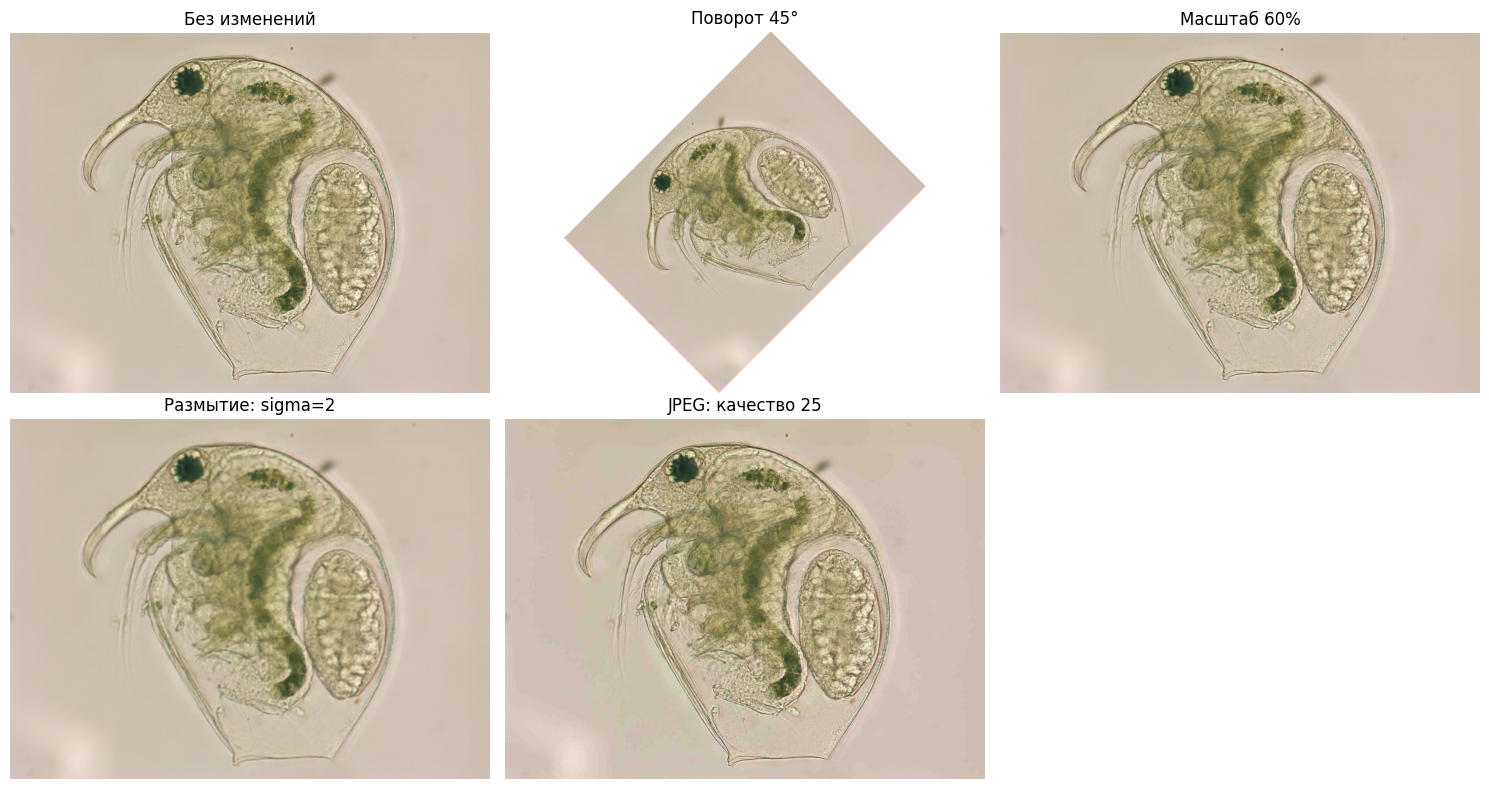

In [53]:
scaling = np.array([[0.6, 0., 0.], [0., 0.6, 0.]])
scaled = cv2.warpAffine(source_image, scaling, (round(width * 0.6), round(height * 0.6)))
blurred = cv2.GaussianBlur(source_image, (9, 9), 2.0)
_, jpeg_bytes = cv2.imencode(".jpg", source_image, [cv2.IMWRITE_JPEG_QUALITY, 25])
compressed = cv2.imdecode(jpeg_bytes, cv2.IMREAD_COLOR)

cases = [
    ("Без изменений", source_image, identity, None),
    ("Поворот 45°", rotated, rotation, valid_rotation),
    ("Масштаб 60%", scaled, scaling, None),
    ("Размытие: sigma=2", blurred, identity, None),
    ("JPEG: качество 25", compressed, identity, None),
]
show_grid([source_image, rotated, scaled, blurred, compressed], ["Без изменений", "Поворот 45°", "Масштаб 60%", "Размытие: sigma=2", "JPEG: качество 25"])

### Поиск и проверка
У преобразованной точки ожидаем координаты `matrix @ [x, y, 1]`.
Если найденная позиция отличается не больше чем на 3 px, считаем пару
геометрически верной.

In [54]:
robust_sift = cv2.SIFT_create(nfeatures=3000, nOctaveLayers=3, contrastThreshold=0.04,
                   edgeThreshold=10, sigma=1.6)
source_points, source_vectors = robust_sift.detectAndCompute(processed[0], None)
matcher = cv2.BFMatcher(cv2.NORM_L2)
robustness = []
robust_details = []

for label, target, matrix, mask in cases:
    gray = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)
    smooth = cv2.GaussianBlur(gray, (3, 3), 0)
    normalized = clahe.apply(smooth)

    target_points, target_vectors = robust_sift.detectAndCompute(normalized, mask)

    forward = ratio_matches(source_vectors, target_vectors)
    backward = ratio_matches(target_vectors, source_vectors)
    reverse = {(m.trainIdx, m.queryIdx) for m in backward}
    matches = [m for m in forward if (m.queryIdx, m.trainIdx) in reverse]
    
    good, bad, errors = [], [], []
    for match in matches:
        x, y = source_points[match.queryIdx].pt
        expected = matrix @ np.array([x, y, 1.])
        actual = np.array(target_points[match.trainIdx].pt)
        error = float(np.linalg.norm(expected - actual))
        errors.append(error)
        if error <= 3:
            good.append(match)
        else:
            bad.append(match)
    robustness.append({"case": label, "target_points": len(target_points),
        "accepted": len(matches), "correct": len(good), "incorrect": len(bad),
        "precision": len(good) / len(matches) if matches else None,
        "median_error_px": float(np.median(errors)) if errors else None})
    robust_details.append((target, target_points, good, bad))

### Таблица результатов
Точность — доля геометрически верных пар среди принятых, а не полнота.
Допуск 3 px задан на изменённом изображении; при уменьшении он соответствует
большей области исходного снимка.

In [55]:
rows = ["| Опыт | Точек на копии | Принято | Верно | Ошибочно | Точность |",
        "|---|---:|---:|---:|---:|---:|"]
for row in robustness:
    precision = f"{row['precision']:.1%}" if row["precision"] is not None else "—"
    rows.append(f"| {row['case']} | {row['target_points']} | {row['accepted']} | "
                f"{row['correct']} | {row['incorrect']} | {precision} |")
display(Markdown("\n".join(rows)))

| Опыт | Точек на копии | Принято | Верно | Ошибочно | Точность |
|---|---:|---:|---:|---:|---:|
| Без изменений | 3002 | 3002 | 3002 | 0 | 100.0% |
| Поворот 45° | 3000 | 2236 | 2233 | 3 | 99.9% |
| Масштаб 60% | 3000 | 1550 | 1550 | 0 | 100.0% |
| Размытие: sigma=2 | 3000 | 734 | 730 | 4 | 99.5% |
| JPEG: качество 25 | 3000 | 2189 | 2188 | 1 | 100.0% |

### Верные и ошибочные совпадения

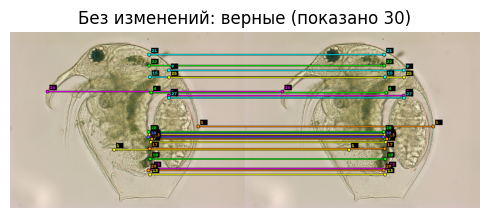

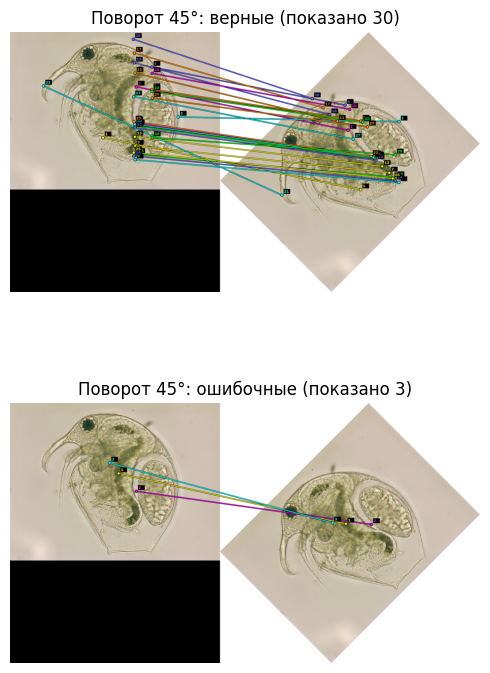

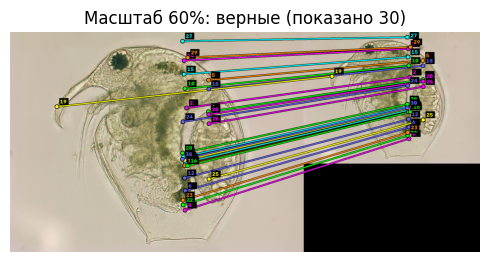

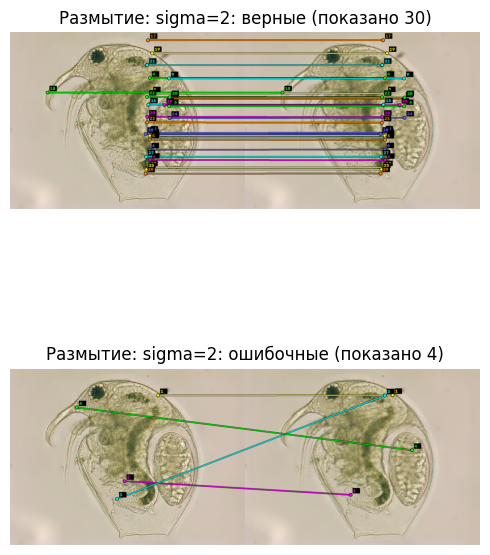

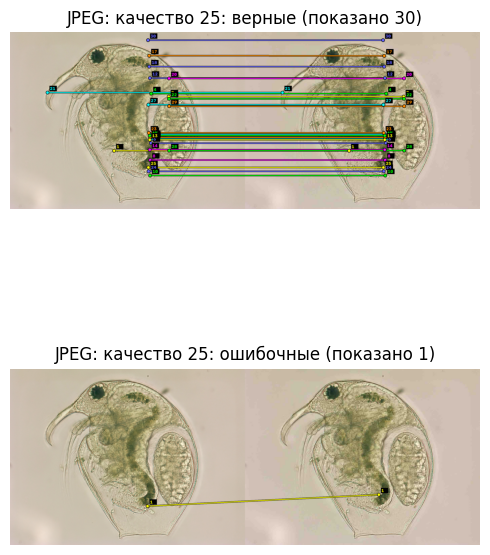

In [56]:
saved_images, saved_points, saved_pairs = images, keypoints, pair_matches
try:
    for row, details in zip(robustness, robust_details):
        target, target_points, good, bad = details
        images = [source_image, target]
        keypoints = [source_points, target_points]
        views, titles = [], []
        for category, matches in [("Верные", good[:30]), ("Ошибочные", bad[:10])]:
            if not matches:
                continue
            pair_matches = {(0, 1): matches}
            view = draw_pair(0, 1)
            views.append(view)
            titles.append(f"{row['case']}: {category.lower()} (показано {len(matches)})")
        if views:
            show_grid(views, titles, columns=1)
finally:
    images, keypoints, pair_matches = saved_images, saved_points, saved_pairs

In [ ]:
lines = ["## Вывод по контрольному опыту"]
for row in robustness:
    precision = f"{row['precision']:.1%}" if row["precision"] is not None else "—"
    lines.append(f"- {row['case']}: {row['correct']} верных из {row['accepted']}; точность {precision}.")
lines.append("\nЭто копии одного снимка: результаты не доказывают устойчивость "
             "к другому ракурсу или различиям организмов. Оценивайте и число верных пар, "
             "и точность. Высокая точность не означает, что найдены все соответствия.")
display(Markdown("\n".join(lines)))